In [1]:
import html
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# NLP y Modelado clásico
import spacy
from spacy.lang.en.stop_words import STOP_WORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

In [2]:
train_df = pd.read_csv("ag_news_train.csv")
test_df = pd.read_csv("ag_news_test.csv")

print(f"Dimensiones Train: {train_df.shape} (8000 muestras)")
print(f"Dimensiones Test:  {test_df.shape} (2000 muestras)")
print("\nDistribución por clase en Train:\n", train_df['label'].value_counts())

Dimensiones Train: (8000, 2) (8000 muestras)
Dimensiones Test:  (2000, 2) (2000 muestras)

Distribución por clase en Train:
 label
Sci_Tech    2000
Business    2000
Sports      2000
World       2000
Name: count, dtype: int64


In [3]:
# Reutilización de la función validada en la Pre-entrega 2
def preprocess_text(text: str) -> str:
    # 1. Decodificar entidades HTML (<, ", etc.)
    text = html.unescape(text)
    # 2. Remover etiquetas HTML completas
    text = re.sub(r'<[^>]+>', ' ', text)
    # 3. Remover enlaces y URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    # 4. Conservar únicamente letras del alfabeto
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # 5. Normalizar a minúsculas y espacios simples
    text = re.sub(r'\s+', ' ', text).strip().lower()
    # 6. Descartar palabras vacías (stop-words) y tokens de 1 solo carácter
    tokens = [w for w in text.split() if w not in STOP_WORDS and len(w) > 1]
    return " ".join(tokens)

print("Preprocesando conjunto de entrenamiento...")
train_df['clean_text'] = train_df['text'].apply(preprocess_text)

print("Preprocesando conjunto de prueba...")
test_df['clean_text'] = test_df['text'].apply(preprocess_text)

y_train = train_df['label']
y_test = test_df['label']

Preprocesando conjunto de entrenamiento...
Preprocesando conjunto de prueba...


In [4]:
# Experimentamos con max_features y ngram_range para analizar la dimensionalidad
experimentos = [
    {"ngram_range": (1, 1), "max_features": 3000, "desc": "Unigramas (Vocabulario reducido)"},
    {"ngram_range": (1, 1), "max_features": 5000, "desc": "Unigramas (Vocabulario medio)"},
    {"ngram_range": (1, 2), "max_features": 5000, "desc": "Unigramas + Bigramas (Vocabulario balanceado)"},
    {"ngram_range": (1, 2), "max_features": 10000, "desc": "Unigramas + Bigramas (Vocabulario amplio)"},
    {"ngram_range": (1, 2), "max_features": None, "desc": "Unigramas + Bigramas (Sin restricción)"},
]

resultados_tfidf = []

for exp in experimentos:
    # FIT solo en train, TRANSFORM en test (Cero Data Leakage)
    vec = TfidfVectorizer(ngram_range=exp["ngram_range"], max_features=exp["max_features"])
    X_tr = vec.fit_transform(train_df['clean_text'])
    X_te = vec.transform(test_df['clean_text'])

    # Entrenamos un baseline rápido de Regresión Logística
    modelo_temp = LogisticRegression(max_iter=1000, random_state=42)
    modelo_temp.fit(X_tr, y_train)
    preds = modelo_temp.predict(X_te)

    macro_f1 = f1_score(y_test, preds, average='macro')
    resultados_tfidf.append({
        "Configuración": exp["desc"],
        "N-Gramas": str(exp["ngram_range"]),
        "Max Features": str(exp["max_features"]),
        "Dimensión Real": X_tr.shape[1],
        "F1-Macro (Test)": round(macro_f1, 4)
    })

pd.DataFrame(resultados_tfidf)

,Configuración,N-Gramas,Max Features,Dimensión Real,F1-Macro (Test)
0,Unigramas (Vocabulario reducido),"(1, 1)",3000,3000,0.8910
1,Unigramas (Vocabulario medio),"(1, 1)",5000,5000,0.8950
2,Unigramas + Bigramas (Vocabulario balanceado),"(1, 2)",5000,5000,0.8951
3,Unigramas + Bigramas (Vocabulario amplio),"(1, 2)",10000,10000,0.8945
4,Unigramas + Bigramas (Sin restricción),"(1, 2)",None,162337,0.8964


In [5]:
# Fijamos la configuración óptima seleccionada: unigramas + bigramas acotados a 5000 features
tfidf_optimo = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_train_vec = tfidf_optimo.fit_transform(train_df['clean_text'])
X_test_vec = tfidf_optimo.transform(test_df['clean_text'])

modelos = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Linear Support Vector (SVC)": LinearSVC(random_state=42, max_iter=2000, dual='auto'),
    "Regresión Logística": LogisticRegression(max_iter=1000, C=1.0, random_state=42)
}

print(f"{'Modelo':<30} | {'F1-Macro':<10} | {'Accuracy':<10}")
print("-" * 55)

for nombre, mod in modelos.items():
    mod.fit(X_train_vec, y_train)
    predicciones = mod.predict(X_test_vec)
    f1 = f1_score(y_test, predicciones, average='macro')
    acc = np.mean(predicciones == y_test)
    print(f"{nombre:<30} | {f1:<10.4f} | {acc:<10.4f}")

Modelo                         | F1-Macro   | Accuracy  
-------------------------------------------------------
Multinomial Naive Bayes        | 0.8902     | 0.8900    
Linear Support Vector (SVC)    | 0.8871     | 0.8870    
Regresión Logística            | 0.8951     | 0.8950    


--- REPORTE DE CLASIFICACIÓN DETALLADO ---
              precision    recall  f1-score   support

    Business     0.8442    0.8560    0.8500       500
    Sci_Tech     0.8705    0.8740    0.8723       500
      Sports     0.9523    0.9580    0.9551       500
       World     0.9139    0.8920    0.9028       500

    accuracy                         0.8950      2000
   macro avg     0.8952    0.8950    0.8951      2000
weighted avg     0.8952    0.8950    0.8951      2000



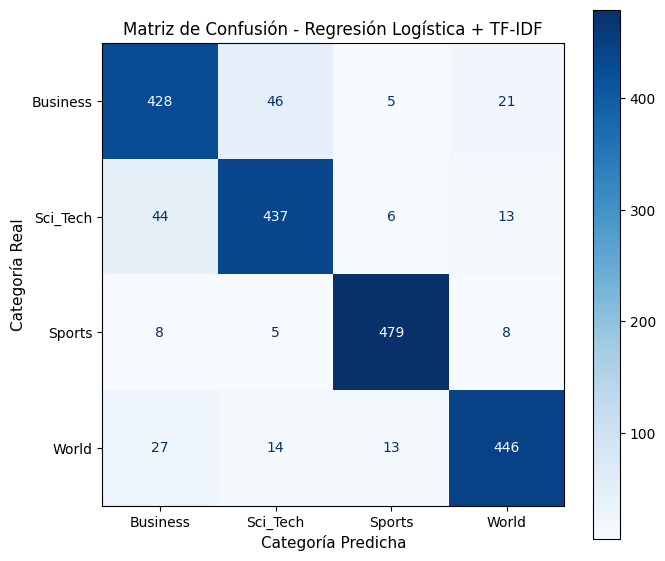

In [6]:
modelo_final = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
modelo_final.fit(X_train_vec, y_train)
y_pred = modelo_final.predict(X_test_vec)

# 1. Classification Report
print("--- REPORTE DE CLASIFICACIÓN DETALLADO ---")
print(classification_report(y_test, y_pred, digits=4))

# 2. Matriz de Confusión Gráfica
fig, ax = plt.subplots(figsize=(7, 6))
labels_clases = sorted(y_test.unique())

disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=labels_clases,
    cmap='Blues',
    values_format='d',
    ax=ax
)
plt.title("Matriz de Confusión - Regresión Logística + TF-IDF", fontsize=12)
plt.xlabel("Categoría Predicha", fontsize=11)
plt.ylabel("Categoría Real", fontsize=11)
plt.grid(False)
plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=300)
plt.show()